# Tarea 2: Modelos Lineales Generalizados (MLG)
## Cuasi-Verosimilitud, Regresión Simplex y Regresión Beta
**Autor:** Full-Stack Data Scientist  
**Entorno:** Python 3 (NumPy, SciPy, Pandas, Matplotlib, Seaborn)


### Punto 1: Demostración Formal en MLG

Considere cualquier MLG con media condicional $\mu_i = \mathbb{E}(Y_i) > 0$, función de varianza $V(\mu_i)$ y enlace:
$$\eta_i = g(\mu_i) = \begin{cases} \mu_i^\lambda, & \text{si } \lambda \ne 0, \\ \log(\mu_i), & \text{si } \lambda = 0. \end{cases}$$

Las ecuaciones de puntuación (score equations) son:
$$U_j(\boldsymbol{\beta}) = \sum_{i=1}^n \frac{y_i - \mu_i}{\phi V(\mu_i)} \frac{\partial \mu_i}{\partial \eta_i} x_{ij} = 0, \quad \forall j=1,\dots,p$$

Dado que $\frac{\partial \mu_i}{\partial \eta_i} = \frac{1}{g'(\mu_i)}$ y cancelando el escalar de dispersión $\phi > 0$:
$$\sum_{i=1}^n \frac{y_i - \hat{\mu}_i}{V(\hat{\mu}_i)} \frac{1}{g'(\hat{\mu}_i)} x_{ij} = 0, \quad j=1,\dots,p$$

**1. Caso $\lambda \ne 0$:**$g'(\mu_i) = \lambda \mu_i^{\lambda-1} \implies \frac{1}{g'(\hat{\mu}_i)} = \frac{\hat{\mu}_i}{\lambda \hat{\eta}_i}$.
Multiplicando por $\hat{\beta}_j$ y sumando sobre $j=1,\dots,p$:
$$\sum_{i=1}^n \frac{y_i - \hat{\mu}_i}{V(\hat{\mu}_i) \lambda \hat{\mu}_i^{\lambda-1}} \underbrace{\left( \sum_{j=1}^p x_{ij}\hat{\beta}_j \right)}_{\hat{\eta}_i = \hat{\mu}_i^\lambda} = \frac{1}{\lambda} \sum_{i=1}^n \frac{\hat{\mu}_i}{\hat{V}_i} (y_i - \hat{\mu}_i) = 0$$
Multiplicando por $\lambda \ne 0$, se obtiene $\sum_{i=1}^n \frac{\hat{\mu}_i}{\hat{V}_i}(y_i - \hat{\mu}_i) = 0$.

**2. Caso $\lambda = 0$:**$g'(\mu_i) = 1/\mu_i \implies \frac{1}{g'(\hat{\mu}_i)} = \hat{\mu}_i$.
Dado que la matriz $\mathbf{X}$ contiene la columna de unos para el intercepto ($x_{i1} = 1$), evaluando en $j=1$:
$$\sum_{i=1}^n \frac{y_i - \hat{\mu}_i}{\hat{V}_i} (\hat{\mu}_i)(1) = \sum_{i=1}^n \frac{\hat{\mu}_i}{\hat{V}_i}(y_i - \hat{\mu}_i) = 0. \quad \blacksquare$$


In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.optimize import minimize
from scipy.special import gammaln
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
print('Entorno científico listo.')

Entorno científico listo.


### Punto 2: Datos de Cebada (`cebada.dat`)
Se analizan 90 observaciones de un experimento factorial (9 lugares x 10 variedades).

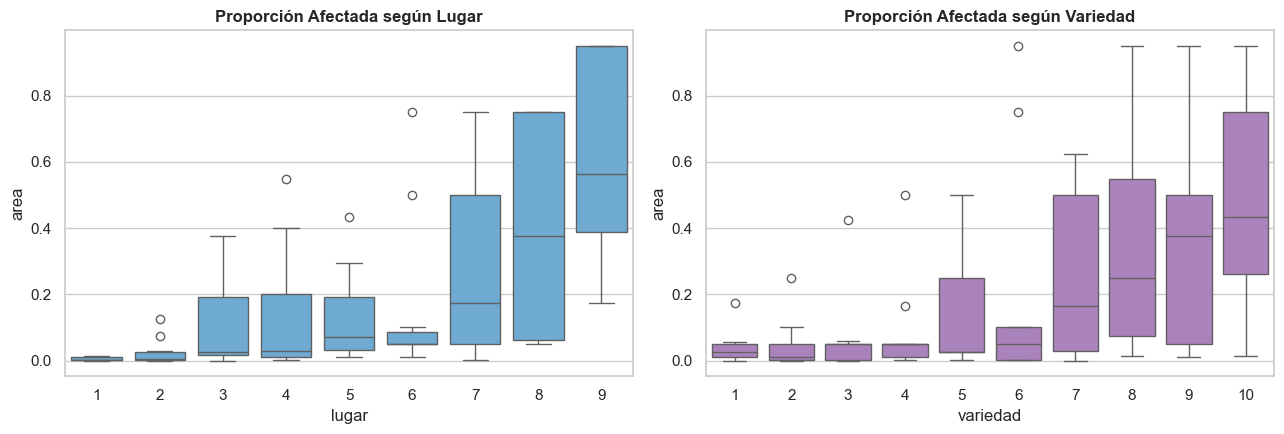

In [2]:
df_c = pd.read_csv('cebada.dat', sep=r'\s+', header=None, names=['area', 'lugar', 'variedad'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x='lugar', y='area', data=df_c, ax=axes[0], color='#5DADE2')
axes[0].set_title('Proporción Afectada según Lugar', fontweight='bold')
sns.boxplot(x='variedad', y='area', data=df_c, ax=axes[1], color='#AF7AC5')
axes[1].set_title('Proporción Afectada según Variedad', fontweight='bold')
plt.tight_layout()
plt.show()

In [3]:
X_lugar = pd.get_dummies(df_c['lugar'], drop_first=True, dtype=float)
X_var = pd.get_dummies(df_c['variedad'], drop_first=True, dtype=float)
X_c = np.column_stack([np.ones(len(df_c)), X_lugar.values, X_var.values])
y_c = df_c['area'].values

def fit_quasi(X, y, var_type='v1', max_iter=100, tol=1e-8):
    n, p = X.shape
    y_adj = (y * (n - 1) + 0.5) / n
    eta = np.log(y_adj / (1.0 - y_adj))
    beta = np.linalg.pinv(X) @ eta
    for _ in range(max_iter):
        eta = X @ beta
        pi = 1.0 / (1.0 + np.exp(-eta))
        pi = np.clip(pi, 1e-6, 1.0 - 1e-6)
        d_eta_d_pi = 1.0 / (pi * (1.0 - pi))
        z = eta + (y - pi) * d_eta_d_pi
        W = pi * (1.0 - pi) if var_type == 'v1' else np.ones(n)
        W_sqrt = np.sqrt(W)
        X_tilde = X * W_sqrt[:, None]
        z_tilde = z * W_sqrt
        beta_new = np.linalg.solve(X_tilde.T @ X_tilde, X_tilde.T @ z_tilde)
        if np.max(np.abs(beta_new - beta)) < tol:
            beta = beta_new
            break
        beta = beta_new
    eta = X @ beta
    pi = 1.0 / (1.0 + np.exp(-eta))
    pi = np.clip(pi, 1e-6, 1.0 - 1e-6)
    v_pi = pi * (1.0 - pi) if var_type == 'v1' else (pi * (1.0 - pi))**2
    r_p = (y - pi) / np.sqrt(v_pi)
    X2 = np.sum(r_p**2)
    phi = X2 / (n - p)
    return {'beta': beta, 'pi': pi, 'residuals': r_p, 'X2': X2, 'phi': phi}

m1 = fit_quasi(X_c, y_c, 'v1')
m2 = fit_quasi(X_c, y_c, 'v2')
print(f'Modelo 1 [V(pi) = pi(1-pi)]:       X2 = {m1["X2"]:.4f} | Dispersion sigma2 = {m1["phi"]:.4f}')
print(f'Modelo 2 [V(pi) = pi^2(1-pi)^2]:   X2 = {m2["X2"]:.4f} | Dispersion sigma2 = {m2["phi"]:.4f}')

Modelo 1 [V(pi) = pi(1-pi)]:       X2 = 6.3922 | Dispersion sigma2 = 0.0888
Modelo 2 [V(pi) = pi^2(1-pi)^2]:   X2 = 71.1703 | Dispersion sigma2 = 0.9885


#### ¿Es posible ajustar una Regresión Simplex a `cebada.dat`?

**Respuesta:** **No es posible de forma directa.**

**Argumentación :**  
La densidad de la distribución Simplex $S^-(\mu, \sigma^2)$ exige soporte abierto estricto $y \in (0, 1)$ y su devianza unitaria es:
$$d(y, \mu) = \frac{(y - \mu)^2}{y(1-y)\mu^2(1-\mu)^2}$$
En `cebada.dat` existen 4 observaciones con ceros exactos ($y = 0.0000$, por ejemplo Lugar 1 Variedades 2 y 3). Cuando $y=0$:
1. El término normalizador $[y(1-y)]^{-3/2} = 0^{-3/2} \to \infty$ produce indeterminación analítica.
2. La devianza unitaria $d(0, \mu) = \frac{\mu^2}{0} \to \infty$, provocando que la log-verosimilitud diverja a $-\infty$.
Por consiguiente, la regresión simplex no puede evaluarse salvo que se aplique una transformación de compresión o un modelo inflado en ceros.

### Punto 3: Datos de Grasa Corporal (`bodyfat.txt`)
Se ajustan y contrastan los modelos de Regresión Simplex y Regresión Beta.

In [4]:
df_b = pd.read_csv('bodyfat.txt', sep=r'\s+', header=None, names=['bodyfat', 'edad'])
df_b['y'] = df_b['bodyfat'] / 100.0
x_b = df_b['edad'].values
y_b = df_b['y'].values
n_b = len(y_b)

# Ajuste Simplex MLE
def simplex_nll(params):
    b0, b1, l_s2 = params
    s2 = np.exp(l_s2)
    mu = 1.0 / (1.0 + np.exp(-(b0 + b1 * x_b)))
    d = ((y_b - mu)**2) / (y_b * (1.0 - y_b) * (mu**2) * ((1.0 - mu)**2))
    return 0.5 * n_b * np.log(2 * np.pi * s2) + 1.5 * np.sum(np.log(y_b * (1.0 - y_b))) + (0.5 / s2) * np.sum(d)

# Ajuste Beta MLE
def beta_nll(params):
    b0, b1, l_phi = params
    phi = np.exp(l_phi)
    mu = 1.0 / (1.0 + np.exp(-(b0 + b1 * x_b)))
    p, q = mu * phi, (1.0 - mu) * phi
    return -np.sum(gammaln(phi) - gammaln(p) - gammaln(q) + (p - 1.0) * np.log(y_b) + (q - 1.0) * np.log(1.0 - y_b))

opt_s = minimize(simplex_nll, [-1.5, 0.01, np.log(0.1)], method='BFGS')
opt_b = minimize(beta_nll, [-1.5, 0.01, np.log(20.0)], method='BFGS')

aic_s = 2 * 3 + 2 * opt_s.fun
bic_s = np.log(n_b) * 3 + 2 * opt_s.fun
aic_b = 2 * 3 + 2 * opt_b.fun
bic_b = np.log(n_b) * 3 + 2 * opt_b.fun

print(f'Simplex: beta0={opt_s.x[0]:.4f}, beta1={opt_s.x[1]:.4f}, sigma2={np.exp(opt_s.x[2]):.4f} | AIC={aic_s:.2f}, BIC={bic_s:.2f}')
print(f'Beta:    beta0={opt_b.x[0]:.4f}, beta1={opt_b.x[1]:.4f}, phi={np.exp(opt_b.x[2]):.4f}    | AIC={aic_b:.2f}, BIC={bic_b:.2f}')
print(f'\nDelta AIC = {aic_s - aic_b:.2f} a favor del modelo Beta.')

Simplex: beta0=-2.0132, beta1=0.0121, sigma2=2.3020 | AIC=-559.49, BIC=-548.91
Beta:    beta0=-1.9881, beta1=0.0118, phi=25.2627    | AIC=-593.23, BIC=-582.66

Delta AIC = 33.74 a favor del modelo Beta.
